In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.io import loadmat
from scipy.stats import kurtosis

In [49]:
# Define the data path
cwd = Path.cwd()

if (cwd / "data").exists():
    project_root = cwd
elif (cwd.parent / "data").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not find project data folder")

data_dir = (project_root / "data" / "cwru" / "raw")

print(data_dir)
list(data_dir.iterdir())

c:\Users\User\Documents\Projects\predictive-maintenance-system\data\cwru\raw


[WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/109.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/122.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/135.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/97.mat')]

In [50]:
# Extract and inspect the file
normal_data = loadmat(data_dir / "97.mat")
type(normal_data)
normal_data.keys()

normal_keys = [
    key 
    for key in normal_data.keys()
    if not key.startswith("__")
]

normal_keys

for key in normal_keys:
    value = normal_data[key]
    print(key, "shape =", value.shape, "dtype =", value.dtype)

X097_DE_time shape = (243938, 1) dtype = float64
X097_FE_time shape = (243938, 1) dtype = float64
X097RPM shape = (1, 1) dtype = uint16


In [51]:
# Automatically find the keys
# DE = drive-end accelerometer
de_key = next(
    key
    for key in normal_keys
    if "DE_time" in key
)
print(de_key)

rpm_key = next(
    key
    for key in normal_keys
    if "RPM" in key
)
print(rpm_key)

X097_DE_time
X097RPM


In [52]:
# Extract the vibration data
# Squeeze the data from 2D (N, 1) to 1D (N,)
normal_signal = normal_data[de_key].squeeze()
normal_signal.shape
type(normal_signal)

numpy.ndarray

In [53]:
# Extract the RPM
normal_rpm = float(
    # Treat it as a Numpy array to squeeze it
    np.asarray(
        normal_data[rpm_key]
    ).squeeze()
)
print(normal_rpm)

# Calculate rotational frequency
rotational_frequency = (normal_rpm / 60)
print("Rotational frequency:", rotational_frequency, "Hz")

1796.0
Rotational frequency: 29.933333333333334 Hz


In [54]:
# Look at the values
normal_signal[:10]

array([ 0.05319692,  0.08866154,  0.09971815,  0.05862092, -0.00458954,
       -0.056952  , -0.07176369, -0.05862092, -0.04652123, -0.04985908])

In [55]:
# Create time axis
sampling_rate = 48000
normal_time = (np.arange(len(normal_signal)) / sampling_rate)

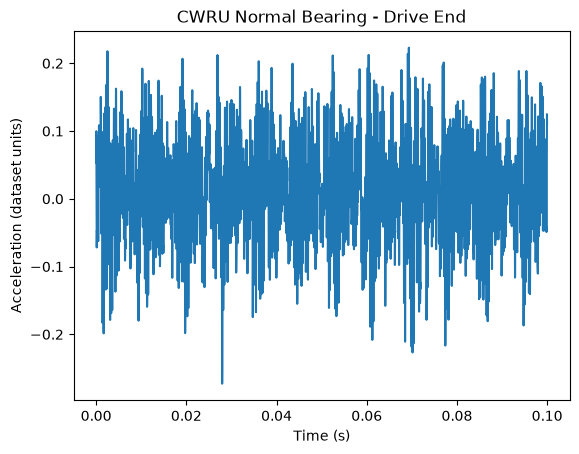

In [56]:
# Plot a portion of graph first (the first 0.1 seconds)
display_duration = 0.1
display_samples = int(display_duration * sampling_rate)

plt.plot(normal_time[:display_samples], normal_signal[:display_samples])
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (dataset units)")
plt.title("CWRU Normal Bearing - Drive End")

plt.show()

In [57]:
# Calculate time-domain features (1 second window)
window_size = sampling_rate
normal_window = normal_signal[:window_size]

mean_value = np.mean(normal_window)
rms = np.sqrt(np.mean(normal_window ** 2))
peak = np.max(np.abs(normal_window))
peak_to_peak = np.ptp(normal_window)
standard_deviation = np.std(normal_window)

crest_factor = peak / rms
kurtosis_value = kurtosis(normal_window, fisher=False, bias=False)

# Print results
print(f"Mean              : {mean_value:.4f}")
print(f"RMS               : {rms:.4f}")
print(f"Peak              : {peak:.4f}")
print(f"Peak-to-peak      : {peak_to_peak:.4f}")
print(f"Standard deviation: {standard_deviation:.4f}")
print(f"Crest factor      : {crest_factor:.4f}")
print(f"Kurtosis          : {kurtosis_value:.4f}")

Mean              : 0.0118
RMS               : 0.0735
Peak              : 0.2866
Peak-to-peak      : 0.5403
Standard deviation: 0.0725
Crest factor      : 3.9006
Kurtosis          : 2.7930


In [58]:
# Convert time-domain to frequency-domain using FFT
def calculate_fft(signal, sampling_rate):
    N = len(signal)
    centered_signal = (signal - np.mean(signal))

    # Use Hann window
    window = np.hanning(N)
    windowed_signal = (centered_signal * window)
    coherent_gain = np.mean(window)

    fft_values = np.fft.rfft(windowed_signal)
    frequencies = np.fft.rfftfreq(N, d=1 / sampling_rate)
    amplitudes = (2 / (N * coherent_gain)) * np.abs(fft_values)

    amplitudes[0] /= 2
    if N % 2 == 0:
        amplitudes[-1] /= 2

    return frequencies, amplitudes

In [59]:
# Calculate FFT
frequencies, amplitudes = calculate_fft(normal_window, sampling_rate)

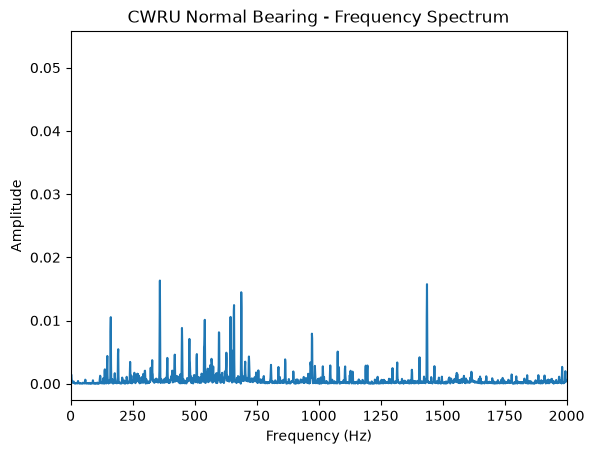

In [60]:
# Plot graph
plt.plot(frequencies, amplitudes)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("CWRU Normal Bearing - Frequency Spectrum")

plt.show()

In [61]:
# Check shaft frequency
shaft_frequency = normal_rpm / 60

# Find nearest FFT bin
shaft_index = np.argmin(np.abs(frequencies - shaft_frequency))

print("Shaft frequency:", shaft_frequency)
print("Nearest FFT frequency:", frequencies[shaft_index])
print("1x amplitude:", amplitudes[shaft_index])

Shaft frequency: 29.933333333333334
Nearest FFT frequency: 30.0
1x amplitude: 0.00043010846260949754


In [62]:
# File Loader
def load_cwru_file(file_path, channel="DE_time"):
    data = loadmat(file_path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    signal_key = next(
        key
        for key in keys
        if channel in key
    )

    rpm_key = next(
        (
            key
            for key in keys
            if "RPM" in key
        ),
        None
    )

    signal = data[signal_key].squeeze()

    rpm = None
    if rpm_key is not None:
        rpm = float(
            np.asarray(
                data[rpm_key]
            ).squeeze()
        )

    return signal, rpm

In [63]:
# Load 109.mat and check
inner_signal, inner_rpm = load_cwru_file(data_dir / "109.mat")
print(inner_signal.shape)
print(inner_rpm)

(243938,)
1796.0


In [ ]:
# Load all four conditions
files = {
    "Normal": "97.mat",
    "Inner race": "109.mat",
    "Ball": "122.mat",
    "Outer race": "135.mat"
}

signals = {}
rpms = {}

for condition, filename in files.items():
    signal, rpm = load_cwru_file(data_dir / filename)
    signals[condition] = signal
    rpms[condition] = rpm

rpms

{'Normal': 1796.0, 'Inner race': 1796.0, 'Ball': 1796.0, 'Outer race': 1796.0}

In [66]:
# Extract 1 second window for each condition
windows = {}

for condition, signal in signals.items():
    windows[condition] = signal[:sampling_rate]

In [67]:
# Feature extraction
def extract_features(signal):
    # Calculate time-domain features
    mean_value = np.mean(signal)
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    peak_to_peak = np.ptp(signal)
    standard_deviation = np.std(signal)

    # Calculate impulsive features
    crest_factor = peak / rms
    kurtosis_value = kurtosis(signal, fisher=False, bias=False)

    return {
        "mean": mean_value,
        "rms": rms,
        "peak": peak,
        "peak_to_peak": peak_to_peak,
        "std": standard_deviation,
        "crest_factor": crest_factor,
        "kurtosis": kurtosis_value,
    }

In [70]:
# Extract features for each signal
feature_rows = []

for condition, signal in windows.items():
    features = extract_features(signal)
    features["condition"] = condition
    feature_rows.append(features)

In [71]:
# Create DataFrame
feature_df = pd.DataFrame(feature_rows)

feature_df

,mean,rms,peak,peak_to_peak,std,crest_factor,kurtosis,condition
0,0.011776,0.073485,0.286638,0.540314,0.072535,3.900647,2.792965,Normal
1,0.084381,0.589870,3.291508,6.064271,0.583804,5.580052,6.028526,Inner race
2,0.032790,0.153186,0.679252,1.196201,0.149636,4.434151,3.091096,Ball
3,0.011383,1.280731,6.541283,12.690272,1.280680,5.107462,6.844890,Outer race
